# Q003: QAOA Max-Cut on Noisy Spin-Qubit Hardware

## Problem
In **Q002** we solved Max-Cut on a four-node ring with QAOA (p = 1) on an ideal simulator. The best possible cut is 4 edges (`0101` or `1010`). At the optimal angles, QAOA reached an expected cut of ⟨C⟩ = 3.0 and returned an optimal cut in about 53% of shots.

Real quantum computers are noisy. **How well does the same QAOA circuit work on a realistic silicon spin-qubit processor?**

1. How many native gates does the circuit need once it is mapped onto the chip's 1D qubit line?
2. How does the fidelity of the whole circuit fall as the qubits' coherence time T₂* gets shorter?
3. How does the *quality of the Max-Cut answer* (⟨C⟩ and P(optimal)) fall over the same range?

We use **SpinPulse** ([arXiv:2601.10435](https://arxiv.org/abs/2601.10435)), Quobly's open-source pulse-level simulator. It models 1/f (pink) noise, which is the dominant noise in spin qubits.

In [1]:
!pip install -q qiskit qiskit-aer spin-pulse

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from spin_pulse import HardwareSpecs, Shape, PulseCircuit, ExperimentalEnvironment
from spin_pulse.environment.noise import NoiseType
%matplotlib inline

## 1. The QAOA circuit and the ideal benchmark
Same graph and angles as Q002. The exact statevector gives the noise-free target values.

In [3]:
n = 4
edges = [(0, 1), (1, 2), (2, 3), (3, 0)]
gamma, beta = np.pi / 4, np.pi / 8          # optimal p = 1 angles (from Q002)

def cut_value(bitstring):
    """Edges cut by a Qiskit bitstring (rightmost character = qubit 0)."""
    bits = bitstring[::-1]
    return sum(bits[i] != bits[j] for i, j in edges)

def qaoa_circuit(measure=True):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for i, j in edges:
        qc.rzz(-gamma, i, j)
    for q in range(n):
        qc.rx(2 * beta, q)
    if measure:
        qc.measure_all()
    return qc

def summarize(counts):
    shots = sum(counts.values())
    avg_cut = sum(cut_value(s) * c for s, c in counts.items()) / shots
    p_opt = sum(c for s, c in counts.items() if cut_value(s) == 4) / shots
    return avg_cut, p_opt

ideal_probs = Statevector(qaoa_circuit(measure=False)).probabilities_dict()
ideal_cut = sum(cut_value(s) * p for s, p in ideal_probs.items())
ideal_opt = sum(p for s, p in ideal_probs.items() if cut_value(s) == 4)
print(f"Ideal (no noise): <C> = {ideal_cut:.3f},  P(optimal cut) = {ideal_opt:.1%}")

Ideal (no noise): <C> = 3.000,  P(optimal cut) = 53.1%


## 2. Map the circuit onto spin-qubit hardware
The hardware's native gates are RX, RY, RZ and RZZ. Two-qubit gates are only allowed between **neighbouring** qubits in a line, but our ring has an edge (3, 0) that wraps around. The transpiler has to insert SWAP gates, each built from several RZZ and single-qubit rotations, so the gate count grows a lot. The hardware parameters are the ones used in the SpinPulse paper.

In [4]:
specs = HardwareSpecs(
    num_qubits=n,
    B_field=0.3,          # single-qubit drive strength
    delta=0.3,
    J_coupling=0.03,      # exchange coupling for RZZ
    rotation_shape=Shape.GAUSSIAN,
    ramp_duration=5,
)

logical = qaoa_circuit(measure=False)
isa = specs.gate_transpile(logical)

print("Original circuit gates:", dict(logical.count_ops()))
print("Native spin-qubit gates:", dict(isa.count_ops()))
print("Depth:", logical.depth(), "->", isa.depth())

Original circuit gates: {'h': 4, 'rzz': 4, 'rx': 4}
Native spin-qubit gates: {'rx': 27, 'rzz': 20, 'ry': 17, 'rz': 12}
Depth: 6 -> 43


## 3. Pulse-level compilation
Every native gate becomes a physical pulse: Gaussian rotations for single-qubit gates and an exchange (J) pulse for RZZ. With no noise, integrating the pulses reproduces the ideal circuit almost perfectly.

Noiseless pulse-level fidelity: 0.999792


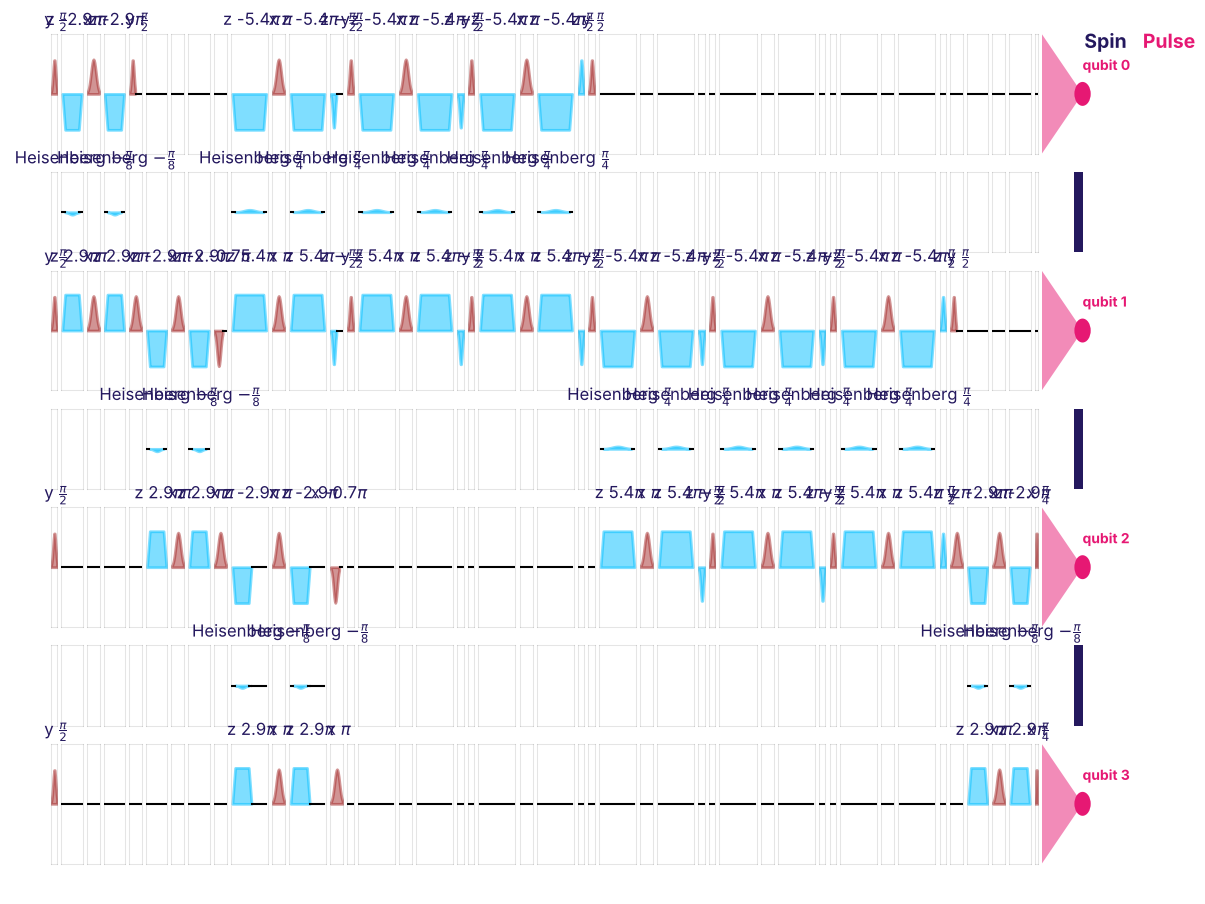

In [5]:
pulse_circ = PulseCircuit.from_circuit(isa, specs)
print(f"Noiseless pulse-level fidelity: {pulse_circ.fidelity(logical):.6f}")
pulse_circ.plot()
plt.show()

## 4. Circuit fidelity under pink noise
We sweep the coherence time T₂*, from long (good qubits) to short (bad qubits). For each value, SpinPulse samples realistic 1/f noise time-traces, integrates the noisy pulses, and averages the gate fidelity against the ideal circuit.

In [6]:
T2_values = [5000, 2000, 1000, 500, 200, 100]
fidelities = []
for T2 in T2_values:
    env = ExperimentalEnvironment(
        hardware_specs=specs, noise_type=NoiseType.PINK, T2S=T2,
        duration=2**14, segment_duration=2**14, seed=1,
    )
    pc = PulseCircuit.from_circuit(isa, specs, exp_env=env)
    fidelities.append(pc.mean_fidelity(env, logical, progress_bar=False))
    print(f"T2* = {T2:>5}:  mean circuit fidelity = {fidelities[-1]:.3f}")

T2* =  5000:  mean circuit fidelity = 0.993


T2* =  2000:  mean circuit fidelity = 0.960


T2* =  1000:  mean circuit fidelity = 0.852


T2* =   500:  mean circuit fidelity = 0.536


T2* =   200:  mean circuit fidelity = 0.107


T2* =   100:  mean circuit fidelity = 0.106


## 5. Solution quality under pink noise
Now we sample measurement outcomes. Each shot runs with a fresh slice of the noise time-trace. **Pass the circuit without measurements:** SpinPulse adds its own and reorders the physical qubits back into logical order. This step takes a few minutes.

In [7]:
# Important: give SpinPulse the circuit WITHOUT measurements (the `isa` from cell 4).
# SpinPulse adds its own final measurement and maps the physical qubits back
# to the logical order. An existing measure_all() would corrupt that mapping.
def noisy_counts(T2, duration=2**19, seed=1):
    env = ExperimentalEnvironment(
        hardware_specs=specs, noise_type=NoiseType.PINK, T2S=T2,
        duration=duration, segment_duration=2**14, seed=seed,
    )
    pc = PulseCircuit.from_circuit(isa, specs, exp_env=env)
    return dict(pc.run_experiment(env, progress_bar=False))   # one shot per noise sample

results = {}
for T2 in T2_values:
    results[T2] = noisy_counts(T2)
    avg_cut, p_opt = summarize(results[T2])
    shots = sum(results[T2].values())
    print(f"T2* = {T2:>5}  ({shots} shots):  <C> = {avg_cut:.3f},  P(optimal) = {p_opt:.1%}")

T2* =  5000  (378 shots):  <C> = 3.048,  P(optimal) = 55.3%


T2* =  2000  (378 shots):  <C> = 3.090,  P(optimal) = 58.5%


T2* =  1000  (378 shots):  <C> = 3.048,  P(optimal) = 54.8%


T2* =   500  (378 shots):  <C> = 2.968,  P(optimal) = 50.8%


T2* =   200  (378 shots):  <C> = 2.413,  P(optimal) = 23.0%


T2* =   100  (378 shots):  <C> = 2.201,  P(optimal) = 18.0%


## 6. Results

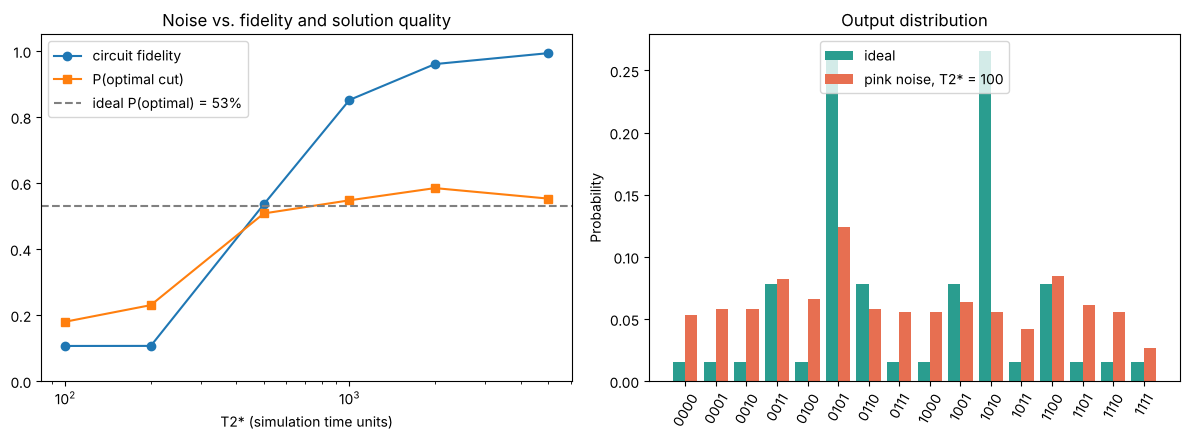

In [8]:
cuts = [summarize(results[T])[0] for T in T2_values]
popts = [summarize(results[T])[1] for T in T2_values]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(T2_values, fidelities, "o-", label="circuit fidelity")
ax[0].plot(T2_values, popts, "s-", label="P(optimal cut)")
ax[0].axhline(ideal_opt, ls="--", c="gray", label=f"ideal P(optimal) = {ideal_opt:.0%}")
ax[0].set_xscale("log"); ax[0].set_xlabel("T2* (simulation time units)")
ax[0].set_ylim(0, 1.05); ax[0].set_title("Noise vs. fidelity and solution quality")
ax[0].legend()

labels = [format(k, "04b") for k in range(16)]
width = 0.4
ideal_vals = [ideal_probs.get(s, 0) for s in labels]
worst = T2_values[-1]
shots_w = sum(results[worst].values())
noisy_vals = [results[worst].get(s, 0) / shots_w for s in labels]
x = np.arange(16)
ax[1].bar(x - width/2, ideal_vals, width, label="ideal", color="#2a9d8f")
ax[1].bar(x + width/2, noisy_vals, width, label=f"pink noise, T2* = {worst}", color="#e76f51")
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, rotation=60)
ax[1].set_ylabel("Probability"); ax[1].set_title("Output distribution")
ax[1].legend(loc="upper center")
plt.tight_layout()
plt.savefig("q003_noise_results.png", dpi=110)
plt.show()

## Solution and discussion

**1. Hardware overhead.** The 12-gate logical circuit becomes **about 76 native gates** (20 RZZ instead of 4), and its depth rises from 6 to over 30. Almost all of the extra cost comes from the single wrap-around edge (3, 0), which needs SWAPs on a 1D chain. Matching the problem graph to the hardware connectivity is often the biggest cost in running QAOA on real devices.

**2. Circuit fidelity** stays near 1 for long T₂*. It drops steeply below about 1000, reaching roughly 0.5–0.8 at T₂* = 500 (depending on how the transpiler routed the circuit) and about 0.1 at T₂* ≤ 200.

**3. Solution quality degrades much more slowly than circuit fidelity.** At T₂* = 500, the full quantum state is noticeably wrong, yet P(optimal) stays at about 50% (ideal: 53%) and ⟨C⟩ stays near 3.0. The reason is that much of the pink noise is *dephasing*, an error in phases that a measurement in the 0/1 basis can't see. Only at T₂* ≈ 100–200 does the output approach random guessing (2 optimal strings out of 16, or 12.5%).

**Takeaway:** for a given application, raw circuit fidelity can be a pessimistic measure of how useful a device is. Pulse-level, noise-accurate simulators like SpinPulse let you check the *task-level* performance directly.

*Notes:*
- Results vary a little from run to run. The transpiler's qubit routing is randomised, and each T₂* uses only about 380–430 shots (roughly ±2.5% statistical error).
- T₂* is in SpinPulse's simulation time units.
- **Try next:** enable spin echo with `HardwareSpecs(..., dynamical_decoupling=DynamicalDecoupling.SPIN_ECHO)`, switch `NoiseType.PINK` to `WHITE` or `QUASISTATIC`, or relabel the graph as a 4-node *line* to remove the SWAP overhead.